In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("marketing_AB.csv")

# Preview the data
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (364522, 7)


/tmp/ipykernel_1003/2677918249.py:6: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("marketing_AB.csv")


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130.0,Monday,20.0
1,1,1119715,ad,False,93.0,Tuesday,22.0
2,2,1144181,ad,False,21.0,Tuesday,18.0
3,3,1435133,ad,False,355.0,Tuesday,10.0
4,4,1015700,ad,False,276.0,Friday,14.0


In [ ]:
# Column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows and user IDs
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate user IDs:", df["user id"].duplicated().sum())

# Numerical summary
display(df.describe())

# Experiment group distribution
display(df["test group"].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364522 entries, 0 to 364521
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Unnamed: 0     364522 non-null  int64  
 1   user id        364522 non-null  int64  
 2   test group     364522 non-null  object 
 3   converted      364521 non-null  object 
 4   total ads      364521 non-null  float64
 5   most ads day   364521 non-null  object 
 6   most ads hour  364521 non-null  float64
dtypes: float64(2), int64(2), object(3)
memory usage: 19.5+ MB

Missing values:
Unnamed: 0       0
user id          0
test group       0
converted        1
total ads        1
most ads day     1
most ads hour    1
dtype: int64

Duplicate rows: 0
Duplicate user IDs: 0


,Unnamed: 0,user id,total ads,most ads hour
count,364522.00000,3.645220e+05,364521.000000,364521.000000
mean,182260.50000,1.318111e+06,33.960189,14.431111
std,105228.58175,2.008408e+05,52.743865,4.819879
min,0.00000,9.000020e+05,1.000000,0.000000
25%,91130.25000,1.155010e+06,8.000000,11.000000
50%,182260.50000,1.324365e+06,18.000000,14.000000
75%,273390.75000,1.491198e+06,39.000000,18.000000
max,364521.00000,1.654483e+06,2065.000000,23.000000


,count
test group,
ad,351186
psa,13336


In [ ]:
# Investigate missing values
display(df[df.isnull().any(axis=1)])

# Check unique values and data types
print("Converted values:")
print(df["converted"].value_counts(dropna=False))

print("\nConverted Python types:")
print(df["converted"].map(type).value_counts())

# Check categorical values
print("\nTest groups:")
print(df["test group"].unique())

print("\nDays:")
print(df["most ads day"].unique())


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
364521,364521,1101267,ad,NaN,NaN,NaN,NaN


Converted values:
converted
False    351724
True      12797
NaN           1
Name: count, dtype: int64

Converted Python types:
converted
<class 'bool'>     364521
<class 'float'>         1
Name: count, dtype: int64

Test groups:
['ad' 'psa']

Days:
['Monday' 'Tuesday' 'Friday' 'Saturday' 'Wednesday' 'Sunday' 'Thursday'
 nan]


In [ ]:
# Create a working copy
df_clean = df.copy()

# Remove unnecessary index column
df_clean = df_clean.drop(columns=["Unnamed: 0"])

# Remove the incomplete record
df_clean = df_clean.dropna().copy()

# Rename columns
df_clean.columns = [
    "user_id",
    "test_group",
    "converted",
    "total_ads",
    "most_ads_day",
    "most_ads_hour"
]

# Fix data types
df_clean["converted"] = df_clean["converted"].astype(int)
df_clean["total_ads"] = df_clean["total_ads"].astype(int)
df_clean["most_ads_hour"] = df_clean["most_ads_hour"].astype(int)

# Verify cleaning
print("Cleaned dataset shape:", df_clean.shape)
print("\nMissing values:")
print(df_clean.isnull().sum())
print("\nData types:")
print(df_clean.dtypes)


Cleaned dataset shape: (364521, 6)

Missing values:
user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64

Data types:
user_id           int64
test_group       object
converted         int64
total_ads         int64
most_ads_day     object
most_ads_hour     int64
dtype: object


In [ ]:
# Validate key business rules
assert df_clean["user_id"].is_unique
assert df_clean["converted"].isin([0, 1]).all()
assert df_clean["test_group"].isin(["ad", "psa"]).all()
assert (df_clean["total_ads"] >= 0).all()
assert df_clean["most_ads_hour"].between(0, 23).all()

print("All validation checks passed!")

# Preview cleaned data
display(df_clean.head())


All validation checks passed!


,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


In [ ]:
# Conversion performance by experiment group
conversion_summary = (
    df_clean.groupby("test_group")
    .agg(
        total_users=("user_id", "count"),
        conversions=("converted", "sum"),
        conversion_rate=("converted", "mean")
    )
    .reset_index()
)

# Convert to percentage
conversion_summary["conversion_rate"] *= 100

display(conversion_summary.round(2))


,test_group,total_users,conversions,conversion_rate
0,ad,351185,12468,3.55
1,psa,13336,329,2.47


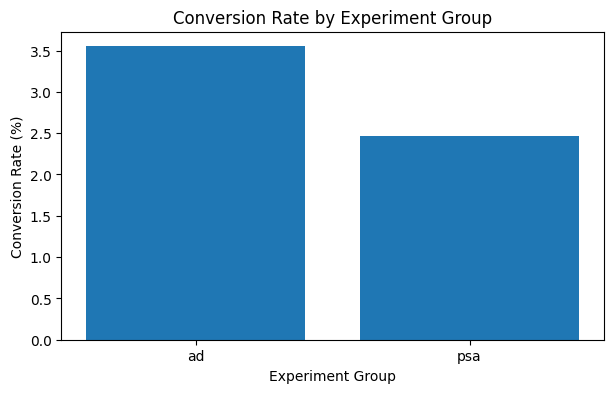

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    conversion_summary["test_group"],
    conversion_summary["conversion_rate"]
)

plt.title("Conversion Rate by Experiment Group")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate (%)")

plt.show()

In [ ]:
# Get conversion rates
rates = conversion_summary.set_index("test_group")["conversion_rate"]

ad_rate = rates["ad"]
control_rate = rates["psa"]

# Calculate conversion lift
lift = ((ad_rate - control_rate) / control_rate) * 100

# Absolute difference in percentage points
difference = ad_rate - control_rate

print(f"Ad Conversion Rate: {ad_rate:.2f}%")
print(f"Control Conversion Rate: {control_rate:.2f}%")
print(f"Absolute Difference: {difference:.2f} percentage points")
print(f"Relative Lift: {lift:.2f}%")


Ad Conversion Rate: 3.55%
Control Conversion Rate: 2.47%
Absolute Difference: 1.08 percentage points
Relative Lift: 43.91%


,count,mean,median,min,max
test_group,,,,,
ad,351185,33.87,18.0,1,2065
psa,13336,36.38,19.0,1,907


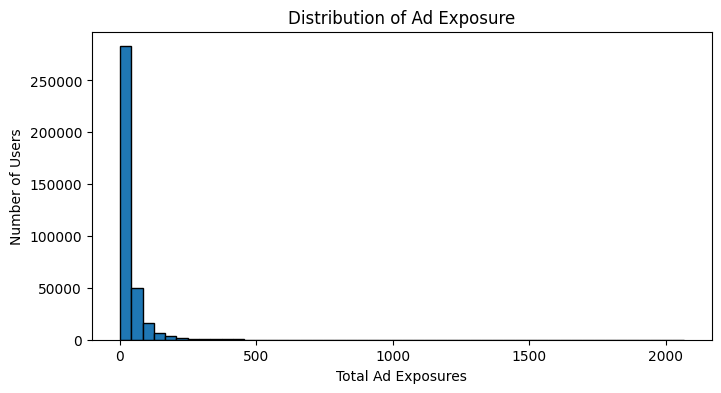

In [ ]:

# Ad exposure statistics by experiment group
exposure_summary = (
    df_clean.groupby("test_group")["total_ads"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(exposure_summary)

# Distribution of ad exposure
plt.figure(figsize=(8, 4))

plt.hist(
    df_clean["total_ads"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Ad Exposure")
plt.xlabel("Total Ad Exposures")
plt.ylabel("Number of Users")

plt.show()


In [ ]:

# Create exposure categories
bins = [0, 5, 10, 20, 50, 100, float("inf")]

labels = [
    "1-5",
    "6-10",
    "11-20",
    "21-50",
    "51-100",
    "101+"
]

df_clean["exposure_group"] = pd.cut(
    df_clean["total_ads"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate conversion rate by exposure and test group
exposure_conversion = (
    df_clean.groupby(
        ["exposure_group", "test_group"],
        observed=True
    )
    .agg(
        total_users=("user_id", "count"),
        conversions=("converted", "sum"),
        conversion_rate=("converted", "mean")
    )
    .reset_index()
)

exposure_conversion["conversion_rate"] *= 100

display(exposure_conversion.round(2))


,exposure_group,test_group,total_users,conversions,conversion_rate
0,1-5,ad,63141,324,0.51
1,1-5,psa,2509,9,0.36
2,6-10,ad,44408,269,0.61
3,6-10,psa,1717,15,0.87
4,11-20,ad,83974,824,0.98
5,11-20,psa,2718,23,0.85
6,21-50,ad,96279,2862,2.97
7,21-50,psa,3611,72,1.99
8,51-100,ad,41393,4449,10.75
9,51-100,psa,1774,91,5.13


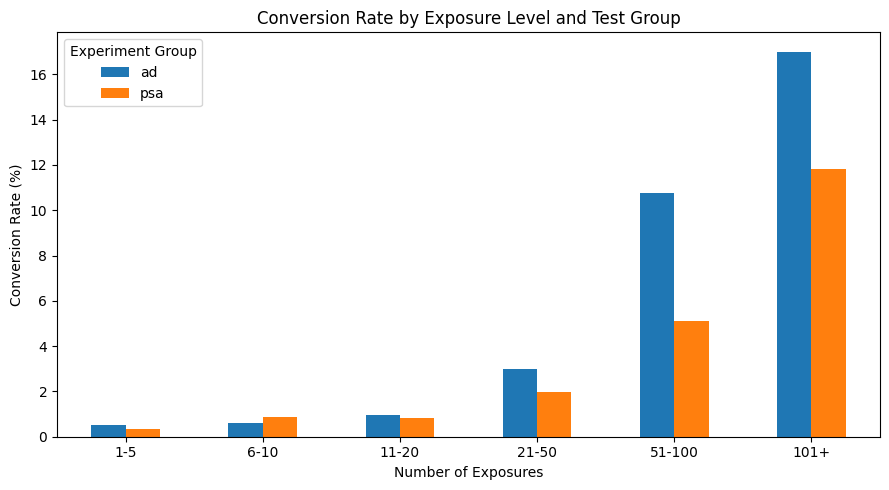

In [ ]:

# Reshape for comparison
exposure_pivot = exposure_conversion.pivot(
    index="exposure_group",
    columns="test_group",
    values="conversion_rate"
)

# Plot conversion rates
ax = exposure_pivot.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Conversion Rate by Exposure Level and Test Group")
plt.xlabel("Number of Exposures")
plt.ylabel("Conversion Rate (%)")
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()


In [ ]:

# Define weekday order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Conversion performance by day and group
daily_conversion = (
    df_clean.groupby(["most_ads_day", "test_group"])
    .agg(
        total_users=("user_id", "count"),
        conversions=("converted", "sum"),
        conversion_rate=("converted", "mean")
    )
    .reset_index()
)

daily_conversion["conversion_rate"] *= 100

# Order weekdays
daily_conversion["most_ads_day"] = pd.Categorical(
    daily_conversion["most_ads_day"],
    categories=day_order,
    ordered=True
)

daily_conversion = daily_conversion.sort_values(
    ["most_ads_day", "test_group"]
)

display(daily_conversion.round(2))


,most_ads_day,test_group,total_users,conversions,conversion_rate
2,Monday,ad,54051,2412,4.46
3,Monday,psa,1866,62,3.32
10,Tuesday,ad,47444,1951,4.11
11,Tuesday,psa,1585,32,2.02
12,Wednesday,ad,46636,1684,3.61
13,Wednesday,psa,2021,43,2.13
8,Thursday,ad,46766,1429,3.06
9,Thursday,psa,2439,55,2.26
0,Friday,ad,57938,1698,2.93
1,Friday,psa,2171,49,2.26


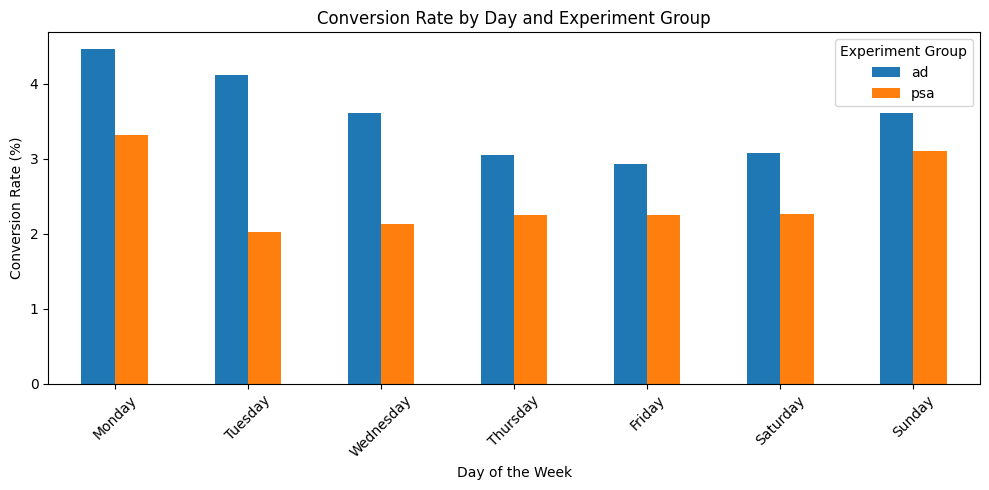

In [ ]:

# Prepare data for visualization
daily_pivot = daily_conversion.pivot(
    index="most_ads_day",
    columns="test_group",
    values="conversion_rate"
)

daily_pivot = daily_pivot.reindex(day_order)

# Plot
ax = daily_pivot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=45
)

plt.title("Conversion Rate by Day and Experiment Group")
plt.xlabel("Day of the Week")
plt.ylabel("Conversion Rate (%)")
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()


In [ ]:

# Calculate conversion performance by hour
hourly_conversion = (
    df_clean.groupby(["most_ads_hour", "test_group"])
    .agg(
        total_users=("user_id", "count"),
        conversions=("converted", "sum"),
        conversion_rate=("converted", "mean")
    )
    .reset_index()
)

# Convert to percentage
hourly_conversion["conversion_rate"] *= 100

display(hourly_conversion.round(2))


,most_ads_hour,test_group,total_users,conversions,conversion_rate
0,0,ad,3780,89,2.35
1,0,psa,177,0,0.00
2,1,ad,3003,57,1.90
3,1,psa,124,0,0.00
4,2,ad,2946,34,1.15
5,2,psa,104,0,0.00
6,3,ad,1536,25,1.63
7,3,psa,55,0,0.00
8,4,ad,485,9,1.86
9,4,psa,16,0,0.00


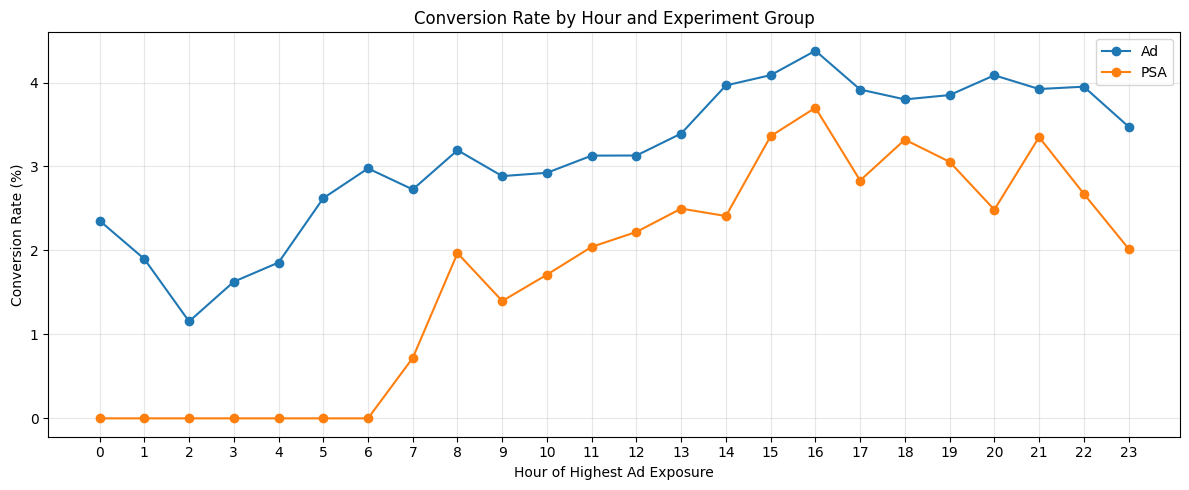

In [ ]:

# Reshape data
hourly_pivot = hourly_conversion.pivot(
    index="most_ads_hour",
    columns="test_group",
    values="conversion_rate"
)

# Plot hourly conversion rates
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_pivot.index,
    hourly_pivot["ad"],
    marker="o",
    label="Ad"
)

plt.plot(
    hourly_pivot.index,
    hourly_pivot["psa"],
    marker="o",
    label="PSA"
)

plt.title("Conversion Rate by Hour and Experiment Group")
plt.xlabel("Hour of Highest Ad Exposure")
plt.ylabel("Conversion Rate (%)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Top 5 hours for each experiment group
top_hours = (
    hourly_conversion
    .sort_values(
        ["test_group", "conversion_rate"],
        ascending=[True, False]
    )
    .groupby("test_group")
    .head(5)
)

display(top_hours.round(2))


,most_ads_hour,test_group,total_users,conversions,conversion_rate
32,16,ad,21696,950,4.38
30,15,ad,27008,1104,4.09
40,20,ad,17939,733,4.09
28,14,ad,26983,1070,3.97
44,22,ad,14910,589,3.95
33,16,psa,838,31,3.70
31,15,psa,1071,36,3.36
43,21,psa,627,21,3.35
37,18,psa,723,24,3.32
39,19,psa,720,22,3.06


In [ ]:

from statsmodels.stats.proportion import proportions_ztest

# Get conversion counts and sample sizes
summary = conversion_summary.set_index("test_group")

conversions = [
    summary.loc["ad", "conversions"],
    summary.loc["psa", "conversions"]
]

sample_sizes = [
    summary.loc["ad", "total_users"],
    summary.loc["psa", "total_users"]
]

# Perform two-sided z-test
z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=sample_sizes,
    alternative="two-sided"
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.8f}")

alpha = 0.05

if p_value < alpha:
    print("Result: Reject the null hypothesis.")
    print("The difference is statistically significant.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("Insufficient evidence of a difference.")


Z-statistic: 6.6714
P-value: 0.00000000
Result: Reject the null hypothesis.
The difference is statistically significant.


In [ ]:

from statsmodels.stats.proportion import confint_proportions_2indep

# Get conversion counts from our summary
summary = conversion_summary.set_index("test_group")

# Calculate the confidence interval
ci_low, ci_high = confint_proportions_2indep(
    count1=int(summary.loc["ad", "conversions"]),
    nobs1=int(summary.loc["ad", "total_users"]),
    count2=int(summary.loc["psa", "conversions"]),
    nobs2=int(summary.loc["psa", "total_users"]),
    compare="diff",
    method="newcomb",
    alpha=0.05
)

print("95% Confidence Interval")
print(f"Lower Bound: {ci_low * 100:.3f} percentage points")
print(f"Upper Bound: {ci_high * 100:.3f} percentage points")

if ci_low > 0:
    print("Conclusion: The interval is entirely above zero.")
else:
    print("Conclusion: The interval includes zero or is below zero.")


95% Confidence Interval
Lower Bound: 0.799 percentage points
Upper Bound: 1.341 percentage points
Conclusion: The interval is entirely above zero.


In [ ]:
# Export cleaned dataset for SQL and Power BI
df_clean.to_csv(
    "marketing_ab_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Shape:", df_clean.shape)


Cleaned dataset exported successfully!
Shape: (364521, 7)
